# Notebook 11 — Inversão do treino: treinar no PulseDB, testar no PTT-PPG

**Sub-etapa 7b** do projeto IC PPG. Endossada pelo Prof. Renan: *"é só inverter a ordem de importar e aplicar"*.

## O que muda em relação ao NB08 (sub-etapa 7a)

| | NB08 (7a) | NB11 (7b, este) |
|---|---|---|
| **Treino** | PTT-PPG (22 sujeitos, PA por registro) | PulseDB CalBased (~1.293 sujeitos, PA por segmento via ABP contínuo) |
| **Teste** | PulseDB | PTT-PPG |
| **Modelo** | carrega `rf_*_vC.joblib` pronto | treina um RandomForest novo no PulseDB |

**Por que isso pode dar mais robustez:** o rótulo de PA do PulseDB vem de ABP contínuo (supervisão fina, quase por ciclo) e há muito mais diversidade de sujeitos. A hipótese é que um modelo treinado nesse conjunto generalize melhor do que o caminho inverso (7a), que falhou.

**Modelo usado:** Versão C — 35 features só-PPG (sem PTT e sem features dependentes de escala), garantindo compatibilidade entre os dois datasets.

## 1. Importações e configuração

In [2]:
import os
import json
import socket
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

warnings.filterwarnings("ignore")
np.random.seed(42)

# Figuras com fundo branco e 300 DPI (padrao do relatorio)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"]   = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.dpi"] = 300

print("Computador:", socket.gethostname())
print("Inicio:", datetime.now().strftime("%d/%m/%Y %H:%M:%S"))

Computador: NtebookLeticia
Inicio: 25/06/2026 13:16:39


## 2. Caminhos e parâmetros

In [3]:
# ─── Raiz unica do projeto (mesma usada nos demais notebooks) ───
BASE_IC            = Path(r"C:\IC_PPG")
PASTA_DADOS        = BASE_IC / "Datasets" / "PTT_PPG"
PASTA_PULSEDB_FEAT = BASE_IC / "Datasets" / "PulseDB_features"
PASTA_MODELO       = BASE_IC / "Modelos_Salvos" / "PTT_PPG"
PASTA_FIGS         = BASE_IC / "Figuras_Geradas"

# ─── Arquivos de entrada ───
# TREINO = PulseDB CalBased (rotulo de PA vindo de ABP continuo, ~1.293 sujeitos)
ARQ_TREINO_PULSEDB = PASTA_PULSEDB_FEAT / "_features_pulsedb_calbased_test.csv"
# TESTE  = PTT-PPG (22 sujeitos, 3 condicoes sit/walk/run)
ARQ_TESTE_PTTPPG   = PASTA_DADOS / "_features_v2_clean.csv"
# Lista oficial das 35 features da Versao C
ARQ_CONFIG         = PASTA_DADOS / "_configuracoes_modelos.json"
# Modelos Versao C ja salvos (usados SO para copiar os mesmos hiperparametros)
ARQ_MODELO_SYS_REF = PASTA_MODELO / "rf_sys_vC.joblib"

# ─── Amostragem do treino ───
# O CalBased e grande. Para um primeiro treino rapido E equilibrado entre
# sujeitos, limitamos a no maximo N ciclos por sujeito. Coloque None para
# usar TODOS os ciclos (treino completo, mais lento).
MAX_CICLOS_POR_SUJEITO = 80

print("Verificacao dos arquivos de entrada:")
print("-" * 70)
for nome, caminho in {
    "Treino PulseDB":  ARQ_TREINO_PULSEDB,
    "Teste PTT-PPG":   ARQ_TESTE_PTTPPG,
    "Config features": ARQ_CONFIG,
}.items():
    existe = caminho.exists()
    print(f"  [{'OK  ' if existe else 'FALTA'}] {nome:<16} {caminho}")
    if not existe:
        raise FileNotFoundError(caminho)

Verificacao dos arquivos de entrada:
----------------------------------------------------------------------
  [OK  ] Treino PulseDB   C:\IC_PPG\Datasets\PulseDB_features\_features_pulsedb_calbased_test.csv
  [OK  ] Teste PTT-PPG    C:\IC_PPG\Datasets\PTT_PPG\_features_v2_clean.csv
  [OK  ] Config features  C:\IC_PPG\Datasets\PTT_PPG\_configuracoes_modelos.json


## 3. Carregar a lista das 35 features (Versão C)

Lê do mesmo arquivo de configuração que o NB08 usa, garantindo que treino e teste usem exatamente o mesmo conjunto de colunas, na mesma ordem.

In [4]:
with open(ARQ_CONFIG, "r", encoding="utf-8") as f:
    configs = json.load(f)

FEATURES_VC = configs["C"]["features"]   # nomes das 35 colunas da Versao C
assert len(FEATURES_VC) == 35, f"Esperado 35 features, veio {len(FEATURES_VC)}"

print(f"Versao C: {len(FEATURES_VC)} features (sem PTT e sem features de escala)")
for i, nome in enumerate(FEATURES_VC, 1):
    print(f"  {i:2d}. {nome}")

Versao C: 35 features (sem PTT e sem features de escala)
   1. cardiac_period_s
   2. heart_rate_bpm
   3. systolic_upstroke_time_s
   4. diastolic_time_s
   5. sut_dt_ratio
   6. w10_total
   7. w10_sys
   8. w10_dia
   9. w10_ratio
  10. w25_total
  11. w25_sys
  12. w25_dia
  13. w25_ratio
  14. w33_total
  15. w33_sys
  16. w33_dia
  17. w33_ratio
  18. w50_total
  19. w50_sys
  20. w50_dia
  21. w50_ratio
  22. w66_total
  23. w66_sys
  24. w66_dia
  25. w66_ratio
  26. w75_total
  27. w75_sys
  28. w75_dia
  29. w75_ratio
  30. crest_factor
  31. skewness
  32. kurtosis
  33. auc
  34. hjorth_mobility
  35. hjorth_complexity


## 4. Carregar TREINO (PulseDB) e TESTE (PTT-PPG)

O arquivo do PulseDB CalBased tem ~344 MB. Para não estourar a memória, lemos **apenas as colunas necessárias** (`usecols`) e já em `float32`. Se mesmo assim a RAM apertar, me avise que eu troco para uma leitura em blocos (`chunksize`).

In [5]:
# Nomes de coluna comuns aos dois datasets (confirmados pela inspecao)
COL_SUJEITO  = "subject"
COL_REGISTRO = "record"
COL_CONDICAO = "condition"
COL_PAS      = "bp_sys_mean"   # PA sistolica (rotulo)
COL_PAD      = "bp_dia_mean"   # PA diastolica (rotulo)

# ---------- TESTE: PTT-PPG (arquivo pequeno, carrega inteiro) ----------
cols_teste = FEATURES_VC + [COL_SUJEITO, COL_REGISTRO, COL_CONDICAO, COL_PAS, COL_PAD]
df_ptt = pd.read_csv(ARQ_TESTE_PTTPPG, usecols=cols_teste)
print(f"TESTE  PTT-PPG : {df_ptt.shape[0]:>7} ciclos | "
      f"{df_ptt[COL_SUJEITO].nunique()} sujeitos | "
      f"PAS [{df_ptt[COL_PAS].min():.0f}-{df_ptt[COL_PAS].max():.0f}] mmHg")

# ---------- TREINO: PulseDB CalBased (usecols + float32 p/ poupar memoria) -------
cols_treino = FEATURES_VC + [COL_SUJEITO, COL_PAS, COL_PAD]
dtype_feats = {c: "float32" for c in FEATURES_VC}
df_pulse = pd.read_csv(ARQ_TREINO_PULSEDB, usecols=cols_treino, dtype=dtype_feats)
print(f"TREINO PulseDB : {df_pulse.shape[0]:>7} ciclos | "
      f"{df_pulse[COL_SUJEITO].nunique()} sujeitos | "
      f"PAS [{df_pulse[COL_PAS].min():.0f}-{df_pulse[COL_PAS].max():.0f}] mmHg (antes da amostragem)")

# ---------- Amostragem equilibrada por sujeito (opcional) ----------
if MAX_CICLOS_POR_SUJEITO is not None:
    df_pulse = (
        df_pulse
        .groupby(COL_SUJEITO, group_keys=False)
        .apply(lambda g: g.sample(n=min(len(g), MAX_CICLOS_POR_SUJEITO), random_state=42))
        .reset_index(drop=True)
    )
    print(f"Apos amostrar ate {MAX_CICLOS_POR_SUJEITO} ciclos/sujeito: "
          f"{df_pulse.shape[0]} ciclos de treino")

# Confirma que as 35 features existem nos DOIS datasets
faltam_treino = [f for f in FEATURES_VC if f not in df_pulse.columns]
faltam_teste  = [f for f in FEATURES_VC if f not in df_ptt.columns]
assert not faltam_treino, f"Faltam no PulseDB: {faltam_treino}"
assert not faltam_teste,  f"Faltam no PTT-PPG: {faltam_teste}"
print("Compatibilidade de features confirmada (35 colunas nos dois).")

TESTE  PTT-PPG :   42305 ciclos | 22 sujeitos | PAS [87-161] mmHg
TREINO PulseDB :  573758 ciclos | 1293 sujeitos | PAS [47-248] mmHg (antes da amostragem)
Apos amostrar ate 80 ciclos/sujeito: 103440 ciclos de treino
Compatibilidade de features confirmada (35 colunas nos dois).


## 5. Treinar o RandomForest no PulseDB

Treinamos do zero, mas copiando os **mesmos hiperparâmetros** do modelo Versão C já salvo (`rf_sys_vC.joblib`), para manter a metodologia consistente. `clone()` cria um modelo novo (não treinado) com a configuração idêntica. NaN é tratado por imputação pela mediana, ajustada só no treino (sem vazamento).

In [6]:
# Matrizes de treino (PulseDB)
X_treino     = df_pulse[FEATURES_VC].values.astype(np.float32)
y_sys_treino = df_pulse[COL_PAS].values
y_dia_treino = df_pulse[COL_PAD].values

# Imputacao de NaN pela mediana (ajustada SO no treino)
imputador = SimpleImputer(strategy="median")
X_treino  = imputador.fit_transform(X_treino)

def novo_rf():
    """RandomForest novo (zerado) com os MESMOS hiperparametros da Versao C.
    Se o modelo de referencia nao existir, usa um padrao razoavel."""
    try:
        ref = joblib.load(ARQ_MODELO_SYS_REF)   # so para ler a configuracao
        return clone(ref)                        # mesma config, porem sem treino
    except Exception:
        return RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)

print("Treinando RandomForest no PulseDB (PAS e PAD)...")
inicio = datetime.now()

rf_sys_inv = novo_rf(); rf_sys_inv.fit(X_treino, y_sys_treino)
rf_dia_inv = novo_rf(); rf_dia_inv.fit(X_treino, y_dia_treino)

print(f"Treino concluido em {(datetime.now()-inicio).total_seconds():.1f} s")
print(f"  n_estimators = {rf_sys_inv.n_estimators} | n_features = {rf_sys_inv.n_features_in_}")

Treinando RandomForest no PulseDB (PAS e PAD)...
Treino concluido em 18.9 s
  n_estimators = 200 | n_features = 35


## 6. Aplicar o modelo no PTT-PPG (predição bruta)

In [7]:
X_teste = df_ptt[FEATURES_VC].values.astype(np.float32)
X_teste = imputador.transform(X_teste)          # MESMA imputacao do treino

df_ptt["y_sys_pred"] = rf_sys_inv.predict(X_teste)
df_ptt["y_dia_pred"] = rf_dia_inv.predict(X_teste)

print("Predicoes brutas (calibration-free) sobre o PTT-PPG:")
print(f"  PAS: faixa [{df_ptt['y_sys_pred'].min():.0f}, {df_ptt['y_sys_pred'].max():.0f}] | "
      f"media {df_ptt['y_sys_pred'].mean():.1f}")
print(f"  PAD: faixa [{df_ptt['y_dia_pred'].min():.0f}, {df_ptt['y_dia_pred'].max():.0f}] | "
      f"media {df_ptt['y_dia_pred'].mean():.1f}")

Predicoes brutas (calibration-free) sobre o PTT-PPG:
  PAS: faixa [101, 159] | media 125.0
  PAD: faixa [54, 95] | media 67.8


## 7. Funções de avaliação (reaproveitadas do NB08)

In [8]:
def metricas_completas(y_real, y_pred):
    """MAE, RMSE, R2, erro medio (ME), desvio (SD) e % dentro de 5/10/15 mmHg."""
    y_real = np.asarray(y_real); y_pred = np.asarray(y_pred)
    if len(y_real) == 0:
        return {k: np.nan for k in ["MAE","RMSE","R2","ME","SD","pct_5","pct_10","pct_15","n"]}
    erros = y_real - y_pred
    abs_erros = np.abs(erros)
    return {
        "MAE":    mean_absolute_error(y_real, y_pred),
        "RMSE":   np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2":     r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan,
        "ME":     float(np.mean(erros)),
        "SD":     float(np.std(erros, ddof=1)) if len(erros) > 1 else 0.0,
        "pct_5":  100 * float(np.mean(abs_erros <= 5)),
        "pct_10": 100 * float(np.mean(abs_erros <= 10)),
        "pct_15": 100 * float(np.mean(abs_erros <= 15)),
        "n":      int(len(y_real)),
    }

def classificar_bhs(pct_5, pct_10, pct_15):
    """Padrao BHS: A (60/85/95), B (50/75/90), C (40/65/85), senao D."""
    if pct_5 >= 60 and pct_10 >= 85 and pct_15 >= 95: return "A"
    if pct_5 >= 50 and pct_10 >= 75 and pct_15 >= 90: return "B"
    if pct_5 >= 40 and pct_10 >= 65 and pct_15 >= 85: return "C"
    return "D"

def classificar_aami(me, sd):
    """Padrao AAMI/ISO 81060-2: passa se |ME| <= 5 e SD <= 8 mmHg."""
    return "PASSA" if (abs(me) <= 5 and sd <= 8) else "FALHA"

def linha_metricas(y_real, y_pred, alvo, cenario, estrato):
    """Monta uma linha de resultado ja com as classificacoes BHS/AAMI."""
    m = metricas_completas(y_real, y_pred)
    m["BHS"]  = classificar_bhs(m["pct_5"], m["pct_10"], m["pct_15"])
    m["AAMI"] = classificar_aami(m["ME"], m["SD"])
    m["alvo"] = alvo; m["cenario"] = cenario; m["estrato"] = estrato
    return m

cols_show = ["alvo","cenario","estrato","n","MAE","RMSE","R2","ME","SD",
             "pct_5","pct_10","pct_15","BHS","AAMI"]
print("Funcoes de avaliacao prontas.")

Funcoes de avaliacao prontas.


## 8. Cenário 1 — Calibration-free (sem ajuste)

O modelo treinado no PulseDB é aplicado direto no PTT-PPG. Este é o teste **honesto de generalização** entre datasets. Avaliamos em "Todos" e também só em "Walk+Run", para comparar de forma justa com o Cenário 2.

In [9]:
mask_wr = df_ptt[COL_CONDICAO].isin(["walk", "run"]).values

linhas = []
for alvo, col_real, col_pred in [("PAS", COL_PAS, "y_sys_pred"),
                                 ("PAD", COL_PAD, "y_dia_pred")]:
    yr = df_ptt[col_real].values
    yp = df_ptt[col_pred].values
    linhas.append(linha_metricas(yr, yp, alvo, "calibration_free", "Todos"))
    linhas.append(linha_metricas(yr[mask_wr], yp[mask_wr], alvo, "calibration_free", "Walk+Run"))

df_calfree = pd.DataFrame(linhas)
print("CENARIO 1 — CALIBRATION-FREE (treino PulseDB -> teste PTT-PPG)")
print("=" * 100)
print(df_calfree[cols_show].round(2).to_string(index=False))

CENARIO 1 — CALIBRATION-FREE (treino PulseDB -> teste PTT-PPG)
alvo          cenario  estrato     n   MAE  RMSE    R2    ME    SD  pct_5  pct_10  pct_15 BHS  AAMI
 PAS calibration_free    Todos 42305 13.17 16.78 -0.78 -7.97 14.77  25.14   47.94   64.94   D FALHA
 PAS calibration_free Walk+Run 28689 12.24 15.92 -0.51 -6.01 14.74  28.99   52.10   68.58   D FALHA
 PAD calibration_free    Todos 42305  9.98 11.83 -1.00  7.70  8.99  26.13   54.27   77.54   D FALHA
 PAD calibration_free Walk+Run 28689 10.20 12.17 -1.07  7.96  9.21  26.33   53.81   74.97   D FALHA


## 9. Cenário 2 — Calibração por sujeito (offset, âncora no repouso)

Cenário clínico: o paciente faz **uma** medição de referência em repouso (braçadeira). Para cada sujeito, calculamos o quanto a predição média no `sit` desviou do valor real de `sit` e aplicamos esse mesmo deslocamento (*offset*) em walk+run.

**Nota metodológica honesta:** como o PTT-PPG tem PA por *registro*, o `sit` fornece um único valor de PA real por sujeito — o que permite corrigir o **offset** (Estratégia A) com segurança. O ajuste de **inclinação** (Estratégia B, que deu MAE 3,63 no domínio PTT-PPG) exigiria ≥ 2 valores de PA de referência por sujeito, que uma única âncora de repouso não oferece. Esse ponto vale registrar na Discussão.

In [10]:
df_ptt["y_sys_pred_off"] = np.nan
df_ptt["y_dia_pred_off"] = np.nan

for subj in sorted(df_ptt[COL_SUJEITO].unique()):
    m_subj = df_ptt[COL_SUJEITO].values == subj
    m_sit  = m_subj & (df_ptt[COL_CONDICAO].values == "sit")
    m_eval = m_subj & np.isin(df_ptt[COL_CONDICAO].values, ["walk", "run"])
    if m_sit.sum() == 0 or m_eval.sum() == 0:
        continue
    # offset = PA real do sit  -  PA media predita no sit
    off_sys = df_ptt.loc[m_sit, COL_PAS].mean() - df_ptt.loc[m_sit, "y_sys_pred"].mean()
    off_dia = df_ptt.loc[m_sit, COL_PAD].mean() - df_ptt.loc[m_sit, "y_dia_pred"].mean()
    df_ptt.loc[m_eval, "y_sys_pred_off"] = df_ptt.loc[m_eval, "y_sys_pred"] + off_sys
    df_ptt.loc[m_eval, "y_dia_pred_off"] = df_ptt.loc[m_eval, "y_dia_pred"] + off_dia

m_ok = df_ptt["y_sys_pred_off"].notna().values
linhas = []
for alvo, col_real, col_off in [("PAS", COL_PAS, "y_sys_pred_off"),
                                 ("PAD", COL_PAD, "y_dia_pred_off")]:
    yr = df_ptt.loc[m_ok, col_real].values
    yp = df_ptt.loc[m_ok, col_off].values
    linhas.append(linha_metricas(yr, yp, alvo, "calibracao_offset", "Walk+Run"))

df_offset = pd.DataFrame(linhas)
print("CENARIO 2 — CALIBRACAO OFFSET (ancora no 'sit', avalia walk+run)")
print("=" * 100)
print(df_offset[cols_show].round(2).to_string(index=False))

CENARIO 2 — CALIBRACAO OFFSET (ancora no 'sit', avalia walk+run)
alvo           cenario  estrato     n  MAE  RMSE   R2   ME   SD  pct_5  pct_10  pct_15 BHS  AAMI
 PAS calibracao_offset Walk+Run 28689 8.97 11.11 0.26 7.01 8.62  33.38   61.94   82.55   D FALHA
 PAD calibracao_offset Walk+Run 28689 4.43  5.74 0.54 1.34 5.58  64.74   93.10   97.94   A PASSA


## 10. Resumo comparativo e leitura do experimento

In [11]:
df_resumo = pd.concat([df_calfree, df_offset], ignore_index=True)

print("RESUMO — INVERSAO DO TREINO (PulseDB -> PTT-PPG)")
print("=" * 100)
print(df_resumo[cols_show].round(2).to_string(index=False))

print("\nCONTEXTO (resultados anteriores, para comparacao)")
print("-" * 100)
print("  PTT-PPG -> PTT-PPG (NB05, calibrado): MAE_PAS = 3.63 | MAE_PAD = 3.08 mmHg")
print("  PTT-PPG -> PulseDB (NB08, 7a):         generalizacao falhou (R2 negativo PAS)")
print()
print("Leitura:")
print("  - Se a inversao der MAE menor / R2 menos negativo que a 7a (mesmo estrato),")
print("    sustenta a hipotese: treinar com mais diversidade e rotulo continuo (PulseDB)")
print("    gera um modelo mais robusto.")
print("  - Compare SEMPRE o mesmo estrato (Walk+Run) entre cenarios e experimentos.")

RESUMO — INVERSAO DO TREINO (PulseDB -> PTT-PPG)
alvo           cenario  estrato     n   MAE  RMSE    R2    ME    SD  pct_5  pct_10  pct_15 BHS  AAMI
 PAS  calibration_free    Todos 42305 13.17 16.78 -0.78 -7.97 14.77  25.14   47.94   64.94   D FALHA
 PAS  calibration_free Walk+Run 28689 12.24 15.92 -0.51 -6.01 14.74  28.99   52.10   68.58   D FALHA
 PAD  calibration_free    Todos 42305  9.98 11.83 -1.00  7.70  8.99  26.13   54.27   77.54   D FALHA
 PAD  calibration_free Walk+Run 28689 10.20 12.17 -1.07  7.96  9.21  26.33   53.81   74.97   D FALHA
 PAS calibracao_offset Walk+Run 28689  8.97 11.11  0.26  7.01  8.62  33.38   61.94   82.55   D FALHA
 PAD calibracao_offset Walk+Run 28689  4.43  5.74  0.54  1.34  5.58  64.74   93.10   97.94   A PASSA

CONTEXTO (resultados anteriores, para comparacao)
----------------------------------------------------------------------------------------------------
  PTT-PPG -> PTT-PPG (NB05, calibrado): MAE_PAS = 3.63 | MAE_PAD = 3.08 mmHg
  PTT-PPG -> Pu

## 11. Figura — dispersão predito × real (PAS)

Painel A: sem calibração. Painel B: com calibração offset. Salva em 300 DPI, fundo branco, com fonte no rodapé (padrão do relatório).

Figura salva em: C:\IC_PPG\Figuras_Geradas\NB11_inversao_scatter_PAS.png


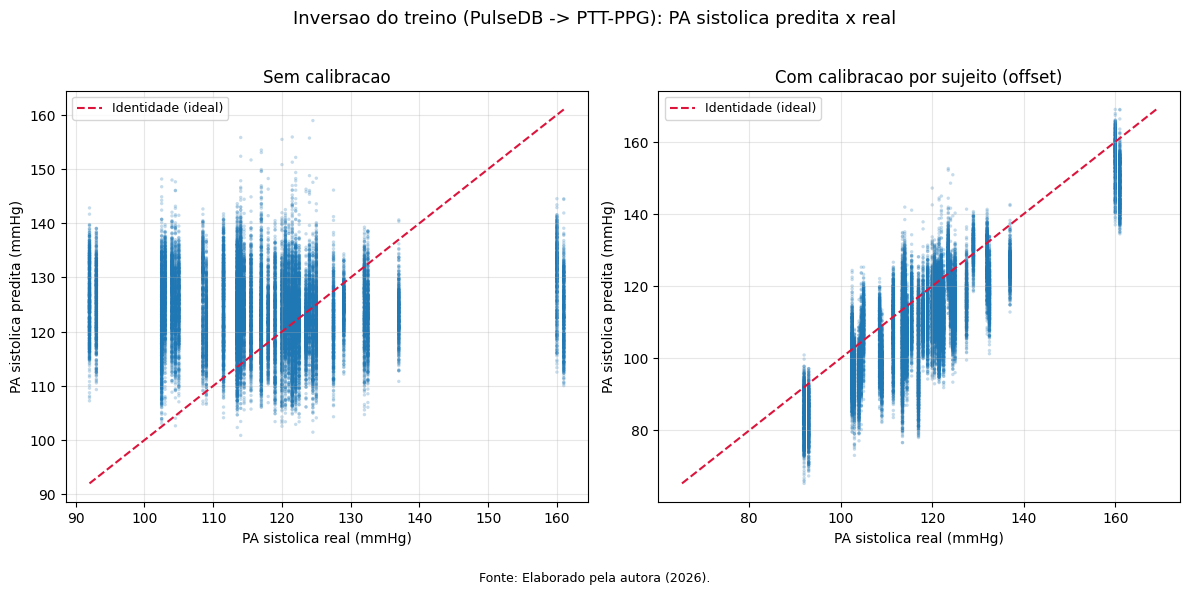

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))

def scatter_pa(ax, y_real, y_pred, titulo):
    ax.scatter(y_real, y_pred, s=6, alpha=0.25, edgecolors="none")
    lo = float(min(np.min(y_real), np.min(y_pred)))
    hi = float(max(np.max(y_real), np.max(y_pred)))
    ax.plot([lo, hi], [lo, hi], "--", color="crimson", linewidth=1.5,
            label="Identidade (ideal)")
    ax.set_xlabel("PA sistolica real (mmHg)")
    ax.set_ylabel("PA sistolica predita (mmHg)")
    ax.set_title(titulo); ax.legend(loc="upper left", fontsize=9); ax.grid(alpha=0.3)

scatter_pa(axes[0], df_ptt.loc[mask_wr, COL_PAS].values,
           df_ptt.loc[mask_wr, "y_sys_pred"].values, "Sem calibracao")
scatter_pa(axes[1], df_ptt.loc[m_ok, COL_PAS].values,
           df_ptt.loc[m_ok, "y_sys_pred_off"].values, "Com calibracao por sujeito (offset)")

fig.suptitle("Inversao do treino (PulseDB -> PTT-PPG): PA sistolica predita x real",
             fontsize=13, y=1.02)
fig.text(0.5, -0.04, "Fonte: Elaborado pela autora (2026).", ha="center", fontsize=9)
fig.tight_layout()

PASTA_FIGS.mkdir(parents=True, exist_ok=True)
caminho_fig = PASTA_FIGS / "NB11_inversao_scatter_PAS.png"
fig.savefig(caminho_fig, dpi=300, bbox_inches="tight")
print("Figura salva em:", caminho_fig)
plt.show()

## 12. Salvar modelos, predições e métricas

In [13]:
PASTA_MODELO.mkdir(parents=True, exist_ok=True)
joblib.dump(rf_sys_inv, PASTA_MODELO / "rf_sys_inversao_PulseDB.joblib")
joblib.dump(rf_dia_inv, PASTA_MODELO / "rf_dia_inversao_PulseDB.joblib")

cols_pred = [COL_SUJEITO, COL_REGISTRO, COL_CONDICAO, COL_PAS, COL_PAD,
             "y_sys_pred", "y_dia_pred", "y_sys_pred_off", "y_dia_pred_off"]
df_ptt[cols_pred].to_csv(PASTA_DADOS / "_predictions_nb11_inversao.csv", index=False)
df_resumo.to_csv(PASTA_DADOS / "_metricas_nb11_inversao.csv", index=False)

print("Artefatos salvos:")
print("  - rf_sys_inversao_PulseDB.joblib / rf_dia_inversao_PulseDB.joblib")
print("  - _predictions_nb11_inversao.csv")
print("  - _metricas_nb11_inversao.csv")

Artefatos salvos:
  - rf_sys_inversao_PulseDB.joblib / rf_dia_inversao_PulseDB.joblib
  - _predictions_nb11_inversao.csv
  - _metricas_nb11_inversao.csv


## 13. Conclusões e próximos passos

- Comparar o **MAE/R² (estrato Walk+Run)** deste notebook com o da sub-etapa 7a (NB08). Melhora → hipótese da diversidade sustentada.
- Se quiser, dá para acrescentar um **Cenário 3** com ajuste de inclinação (Estratégia B), calibrando em `sit+walk` e testando em `run` — me avise que eu incluo.
- Levar o resultado (tabela + figura) para a Discussão do relatório/artigo, conectando com a falha de generalização da 7a.

In [14]:
print(f"Notebook 11 (inversao) concluido em: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")

Notebook 11 (inversao) concluido em: 25/06/2026 13:17:15


In [15]:
# ─── Cenario 3: ESTRATEGIA B (slope+intercept), calibra em sit+walk, testa em run ───
# sit e walk tem valores reais de PA DIFERENTES -> 2 referencias por sujeito,
# o suficiente para ajustar inclinacao (a) e intercepto (b): PA_corr = a*PA_pred + b
df_ptt["y_sys_pred_slope"] = np.nan
df_ptt["y_dia_pred_slope"] = np.nan
for subj in sorted(df_ptt[COL_SUJEITO].unique()):
    m_subj = df_ptt[COL_SUJEITO].values == subj
    m_cal  = m_subj & np.isin(df_ptt[COL_CONDICAO].values, ["sit", "walk"])  # 2 referencias
    m_run  = m_subj & (df_ptt[COL_CONDICAO].values == "run")                 # teste
    if m_cal.sum() < 2 or m_run.sum() == 0:
        continue
    for cp, cr, cout in [("y_sys_pred", COL_PAS, "y_sys_pred_slope"),
                         ("y_dia_pred", COL_PAD, "y_dia_pred_slope")]:
        reg = LinearRegression()
        reg.fit(df_ptt.loc[m_cal, [cp]].values, df_ptt.loc[m_cal, cr].values)
        df_ptt.loc[m_run, cout] = reg.predict(df_ptt.loc[m_run, [cp]].values)

# Compara os 3 tratamentos no MESMO conjunto de teste (run)
m_run_all = (df_ptt[COL_CONDICAO].values == "run") & df_ptt["y_sys_pred_slope"].notna().values
linhas = []
for alvo, cr, c_free, c_off, c_slope in [
    ("PAS", COL_PAS, "y_sys_pred", "y_sys_pred_off", "y_sys_pred_slope"),
    ("PAD", COL_PAD, "y_dia_pred", "y_dia_pred_off", "y_dia_pred_slope"),
]:
    yr = df_ptt.loc[m_run_all, cr].values
    linhas.append(linha_metricas(yr, df_ptt.loc[m_run_all, c_free].values,  alvo, "cal_free",      "Run"))
    linhas.append(linha_metricas(yr, df_ptt.loc[m_run_all, c_off].values,   alvo, "offset_sit",    "Run"))
    linhas.append(linha_metricas(yr, df_ptt.loc[m_run_all, c_slope].values, alvo, "slope_sitwalk", "Run"))
df_cenario3 = pd.DataFrame(linhas)
print("CENARIO 3 — COMPARACAO NO ESTRATO 'RUN' (mesmo conjunto de teste)")
print("=" * 100)
print(df_cenario3[cols_show].round(2).to_string(index=False))

CENARIO 3 — COMPARACAO NO ESTRATO 'RUN' (mesmo conjunto de teste)
alvo       cenario estrato     n   MAE  RMSE    R2    ME    SD  pct_5  pct_10  pct_15 BHS  AAMI
 PAS      cal_free     Run 14426 11.57 14.98 -0.50 -5.75 13.84  29.98   54.10   71.19   D FALHA
 PAS    offset_sit     Run 14426  8.93 11.28  0.15  7.13  8.74  35.61   63.31   82.17   D FALHA
 PAS slope_sitwalk     Run 14426  3.06  3.89  0.90  1.27  3.67  79.35   99.08   99.89   A PASSA
 PAD      cal_free     Run 14426 10.37 12.44 -1.13  8.37  9.20  25.66   54.89   74.34   D FALHA
 PAD    offset_sit     Run 14426  4.60  6.18  0.47  1.62  5.97  65.21   91.32   96.26   A PASSA
 PAD slope_sitwalk     Run 14426  2.79  3.89  0.79  0.56  3.85  85.17   95.47  100.00   A PASSA


Figura salva em: C:\IC_PPG\Figuras_Geradas\NB11_cenario3_run_PAS.png


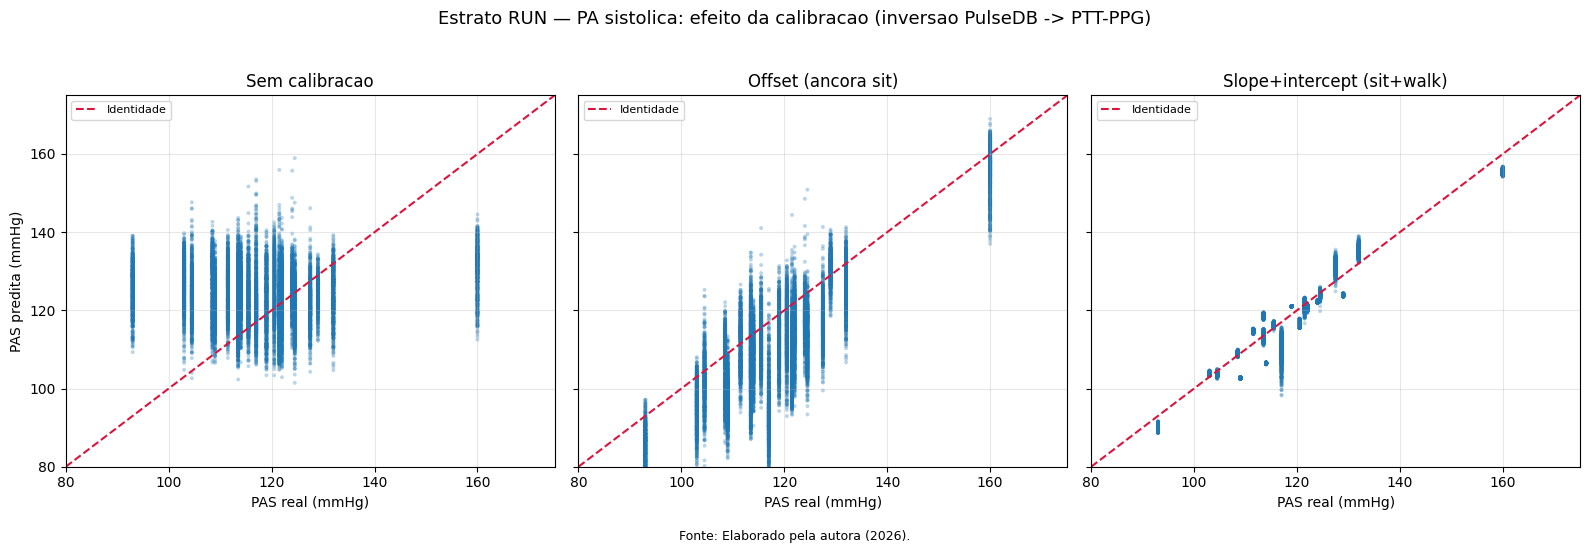

In [16]:
# Figura do Cenario 3: PA sistolica no 'run', os 3 tratamentos lado a lado
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
paineis = [("y_sys_pred", "Sem calibracao"),
           ("y_sys_pred_off", "Offset (ancora sit)"),
           ("y_sys_pred_slope", "Slope+intercept (sit+walk)")]
yr = df_ptt.loc[m_run_all, COL_PAS].values
for ax, (col, titulo) in zip(axes, paineis):
    yp = df_ptt.loc[m_run_all, col].values
    ax.scatter(yr, yp, s=8, alpha=0.30, edgecolors="none")
    lo, hi = 80, 175
    ax.plot([lo, hi], [lo, hi], "--", color="crimson", lw=1.5, label="Identidade")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("PAS real (mmHg)"); ax.set_title(titulo)
    ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("PAS predita (mmHg)")
fig.suptitle("Estrato RUN — PA sistolica: efeito da calibracao (inversao PulseDB -> PTT-PPG)",
             y=1.03, fontsize=13)
fig.text(0.5, -0.03, "Fonte: Elaborado pela autora (2026).", ha="center", fontsize=9)
fig.tight_layout()
caminho_fig3 = PASTA_FIGS / "NB11_cenario3_run_PAS.png"
fig.savefig(caminho_fig3, dpi=300, bbox_inches="tight")
print("Figura salva em:", caminho_fig3); plt.show()